# Problem 1

a). What is the data used for (explain this in a well-written paragraph)? [5 points]


This Data set from https://archive.ics.uci.edu/dataset/547/algerian+forest+fires+dataset is a combination of two data sets for two different regions of Algeria. We will be using the first one, the Bejaia Region Dataset. This data set has new instance for each day and spans four months, June 1st 2012 to September 30th 2012. It contains daily meteorological data (temperature, humidity, wind, rain) and fire danger indices (FFMC, DMC, DC, ISI, BUI, FWI). The final attribute "Classes" charts weather there was a fire that day or not. This dataset helps researchers build and evaluate models that estimate forest fire risk based on weather and fuel conditions.



b). Who (or what organization) uploaded the data? [1 point]


Faroudja Abid

Center for Development of Advanced Technologies (CDTA)

c). How many attributes and how many entries are included in the data?<br>
    a. How many numerical attributes? [1 point]<br>
    b. How many categorical attributes? [1 point]<br>
    c. For the categorical attributes, would you suggest integer encoding (label encoding) or
        one-hot encoding? And why? Answer this for each categorical attribute. [3 points]



Categorical: one attributes, Classes, which has two options {fire, not_fire}. The variable table lists another for region, however this is not an actual attribute column in the data set and is used to split up the two datasets in the original csv file.<br>

Numerical: thirteen (integer and continuous )<br>

There are only two options for the Classes attribute, {fire, not_fire}. So even though they ard not ordinal, we can use label encoding to keep them in the same column.



d) Missing values:
a. Are there missing values in this dataset? [1 point]
b. If so, for each attribute, what is the proportion of the data that is missing? [4 points]
c. What is the proportion of the missing data overall? (You can use the plots to summarize
this data and explain each answer). [1 point]

There are no missing values in this data set. <br>
For each attribute: 0% missing <br>
Overall proportion: 0% missing <br>

e) What is the most interesting thing about this dataset to you? Explain this in a well-written
paragraph. [6 points]

f) Out of all the attributes in this dataset, what do you think are the most descriptive attributes?
(before doing any data analysis)? [5 points]

We think that FWI be most predictive because it uses some of the other attributes to calculated and predict the likelihood of a fire. We also think that drought code and temperature will have a high impact.

# Problem 2

a) Write a function that computes the multi-dimensional mean of the numerical attributes. You
should return the answer as a 2D NumPy array. [5 points]


In [17]:
import numpy as np

X1 = np.array([20, 3, 1 , 3, 6, 4, 8])
X2 = np.array([1.7, 2.4, 1.2, 3.1, 3.3, 8.4, 6.5])
X3 = np.array([[1, 2, 3],
               [4, 5, 6],
               [7, 8, 9]])

def mean(X):
  sum = 0
  for x_i in X:
    sum += x_i
  x_hat = sum/len(X)
  return x_hat


def multi_dimension_mean(X):
    mean_array = np.zeros(X.shape[1])

    for col in range(X.shape[1]):
        mean_array[col] = mean(X[:,col])

    return mean_array.reshape(1, -1)

#for non numby arrays
def multi_dimension_mean_Arrays(X):
    n_rows = len(X)
    n_cols = len(X[0])
    mean_array = []
    for col in range(n_cols):
        col_sum = 0
        for row in range(n_rows):
            col_sum += X[row][col]
        mean_array.append(col_sum / n_rows)
    return [mean_array]


multi_dimension_mean(X3)

array([[4., 5., 6.]])

In [28]:

#standard deviation
def std(X):
    x_hat = mean(X)
    variance = sum((x - x_hat) ** 2 for x in X) / (len(X) - 1)
    return variance ** 0.5

b) A function to calculate sample variance of a given attribute. [5 points]


In [5]:
def variance(X):
    var_x0 = np.sum((X-X.mean())**2) / (X.size-1)
    return var_x0

var = variance(X1)
print(var)
# np.var(X1, ddof=1) # for checking if value is correct

40.95238095238095


c) A function to calculate sample covariance between two given attributes. [5 points]


In [6]:
def covariance(X1, X2):
    X1_hat = mean(X1)
    X2_hat = mean(X2)
    print()
    covarianceX12 = 0
    for i in range(len(X1)):
        X1_difference = (X1[i] - X1_hat)
        X2_difference = (X2[i] - X2_hat)
        covarianceX12 += (X1_difference * X2_difference)

    covarianceX12 = covarianceX12/(len(X1) - 1)
    return covarianceX12

cov = covariance(X1, X2)
print(cov)
# np.cov(X1, X2)[0, 1] # for checking if value is correct


-2.3166666666666673


d) A function that calculates the covariance matrix. (You can use the functions that you have
created in b and c). [5 points]

In [7]:
def covariance_matrix(X):
    num_features = X.shape[1]
    cov_matrix = np.zeros((num_features, num_features))

    for i in range(num_features):
        for j in range(num_features):
            cov_matrix[i, j] = covariance(X[:,i], X[:,j])

    return cov_matrix

covar_matrix = covariance_matrix(X3)
print(covar_matrix)
# np.cov(X3, rowvar=False) # for checking if value is correct










[[9. 9. 9.]
 [9. 9. 9.]
 [9. 9. 9.]]


e) A function to calculate the correlation coefficient between two attributes. [5 points]


In [8]:
def correlation_coef(X1, X2):
    cov = covariance(X1, X2)
    std_X1 = variance(X1) ** 0.5
    std_X2 = variance(X2) ** 0.5

    return cov / (std_X1 * std_X2)

coef = correlation_coef(X1, X2)
print(coef)
# np.corrcoef(X1, X2)[0, 1] # for checking if value is correct


-0.1363097016702045


f) A function that normalizes the attributes in a 2D NumPy array using z-score normalization. [5
points]

In [24]:
def z_score_normalize_array(X):
    num_rows = len(X)
    num_cols = len(X[0])
    normalized_data = []

    for row_index in range(num_rows):
        normalized_row = []
        for col_index in range(num_cols):
            column_values = [X[r][col_index] for r in range(num_rows)]
            col_mean = mean(column_values)
            col_std = std(column_values)
            if col_std != 0:
                normalized_value = (X[row_index][col_index] - col_mean) / col_std
            else:
                normalized_value = 0
            normalized_row.append(normalized_value)
        normalized_data.append(normalized_row)

    return normalized_data


g) A function that normalizes the attributes in a 2D NumPy array using range normalization. [5
points]


In [26]:
def range_normalize_array(X):
    num_rows = len(X)
    num_cols = len(X[0])
    normalized_data = []
    for row_index in range(num_rows):
        normalized_row = []
        for col_index in range(num_cols):
            column_values = [X[r][col_index] for r in range(num_rows)]
            col_min = min(column_values)
            col_max = max(column_values)
            if col_max != col_min:
                normalized_value = (X[row_index][col_index] - col_min) / (col_max - col_min)
            else:
                normalized_value = 0
            normalized_row.append(round(normalized_value, 3))
        normalized_data.append(normalized_row)
    return normalized_data

h) A function that will compute the covariance matrix of a dataset. [5 points]


i) A function that will label-encode a 2D categorical data array that is passed as an input. The
function can expect that the user is passing a 2D array with attributes that are only categorical,
and the function should output a new data matrix with the converted label-encoded (integerencoded) data. [5 points]


In [35]:
def label_encode(data, column_index):

    unique_values = []
    for row in data:
        value = row[column_index]
        if value not in unique_values:
            unique_values.append(value)

    encoded_data = []

    for row in data:

        current_value = row[column_index]

        label = None
        for i in range(len(unique_values)):
            if current_value == unique_values[i]:
                label = i
                break

        new_row = []
        for j in range(len(row)):
            if j == column_index:
                new_row.append(label)
            else:
                new_row.append(row[j])

        encoded_data.append(new_row)

    return encoded_data



j) One-Hot Encoding

In [32]:



def one_hot_encode(data, column_index):

    unique_values = []
    for row in data:
        value = row[column_index]
        if value not in unique_values:
            unique_values.append(value)

    unique_values.sort()

    encoded_data = []

    for row in data:

        current_value = row[column_index]

        one_hot_vector = []
        for value in unique_values:
            if current_value == value:
                one_hot_vector.append(1)
            else:
                one_hot_vector.append(0)

        new_row = []
        for i in range(len(row)):
            if i == column_index:
                for bit in one_hot_vector:
                    new_row.append(bit)
            else:
                new_row.append(row[i])

        encoded_data.append(new_row)

    return encoded_data




# Problem 3

a) First, calculate the multi-dimensional mean and covariance matrix of the numerical portion of
the data. [2 points]

In [163]:


data = np.genfromtxt('Bejaia_Region_DataSet.csv', delimiter=',', skip_header=1)

multi_dimension_mean(data)

array([[1.57540984e+01, 7.50000000e+00, 2.01200000e+03, 3.11803279e+01,
        6.79754098e+01, 1.60000000e+01, 8.42622951e-01, 7.46729508e+01,
        1.23147541e+01, 5.31606557e+01, 3.65573770e+00, 1.54262295e+01,
        5.57786885e+00,            nan]])

b) Then, convert all the categorical data attributes to numerical attributes using label encoding or
one-hot encoding. [5 points]

In [36]:
data = []

with open('Bejaia_Region_DataSet.csv', 'r') as f:
    next(f)  # skip header
    for line in f:
        row = line.strip().split(',')
        data.append(row)

# label encode row 13
# Fire:0, Not Fire: 1
data = label_encode(data, 13)

data_numeric = []

#convert type from string to int/float
for row in data:
    new_row = []
    for value in row:
        # Try converting to int first, if it fails, convert to float
        try:
            new_row.append(int(value))
        except ValueError:
            new_row.append(float(value))
    data_numeric.append(new_row)


for row in data_numeric:
    print(row)



[1, 6, 2012, 29, 57, 18, 0, 65.7, 3.4, 7.6, 1.3, 3.4, 0.5, 0]
[2, 6, 2012, 29, 61, 13, 1.3, 64.4, 4.1, 7.6, 1, 3.9, 0.4, 0]
[3, 6, 2012, 26, 82, 22, 13.1, 47.1, 2.5, 7.1, 0.3, 2.7, 0.1, 0]
[4, 6, 2012, 25, 89, 13, 2.5, 28.6, 1.3, 6.9, 0, 1.7, 0, 0]
[5, 6, 2012, 27, 77, 16, 0, 64.8, 3, 14.2, 1.2, 3.9, 0.5, 0]
[6, 6, 2012, 31, 67, 14, 0, 82.6, 5.8, 22.2, 3.1, 7, 2.5, 1]
[7, 6, 2012, 33, 54, 13, 0, 88.2, 9.9, 30.5, 6.4, 10.9, 7.2, 1]
[8, 6, 2012, 30, 73, 15, 0, 86.6, 12.1, 38.3, 5.6, 13.5, 7.1, 1]
[9, 6, 2012, 25, 88, 13, 0.2, 52.9, 7.9, 38.8, 0.4, 10.5, 0.3, 0]
[10, 6, 2012, 28, 79, 12, 0, 73.2, 9.5, 46.3, 1.3, 12.6, 0.9, 0]
[11, 6, 2012, 31, 65, 14, 0, 84.5, 12.5, 54.3, 4, 15.8, 5.6, 1]
[12, 6, 2012, 26, 81, 19, 0, 84, 13.8, 61.4, 4.8, 17.7, 7.1, 1]
[13, 6, 2012, 27, 84, 21, 1.2, 50, 6.7, 17, 0.5, 6.7, 0.2, 0]
[14, 6, 2012, 30, 78, 20, 0.5, 59, 4.6, 7.8, 1, 4.4, 0.4, 0]
[15, 6, 2012, 28, 80, 17, 3.1, 49.4, 3, 7.4, 0.4, 3, 0.1, 0]
[16, 6, 2012, 29, 89, 13, 0.7, 36.1, 1.7, 7.6, 0, 2.2, 0,

c) If your data has missing values, fill these values with attribute mean. [3 points]


There are no missing attributes

## Answer the following questions once you have completed Problem 3 (b) and (c).


d) Recalculate the multi-dimensional mean of the data matrix after the transformation (categorical
attributes are now numerical). [2 points]


In [23]:
multi_dem_mean_Data_numerical = multi_dimension_mean_Arrays(data_numeric)
for row in multi_dem_mean_Data_numerical:
    print(row)

[15.754098360655737, 7.5, 2012.0, 31.18032786885246, 67.97540983606558, 16.0, 0.8426229508196718, 74.67295081967211, 12.31475409836066, 53.16065573770489, 3.6557377049180304, 15.426229508196723, 5.577868852459019, 0.5163934426229508]


e) What is the new covariance matrix of the data (categorical attributes are now numerical). [3
points]

f) Choose 4 pairs of numerical attributes that you think might be related. Create scatter plots for
these 4 pairs of attributes, along with the description and analysis of why these pairs of
attributes are related and how the scatter plot does or does not support your intuition. [5
points]

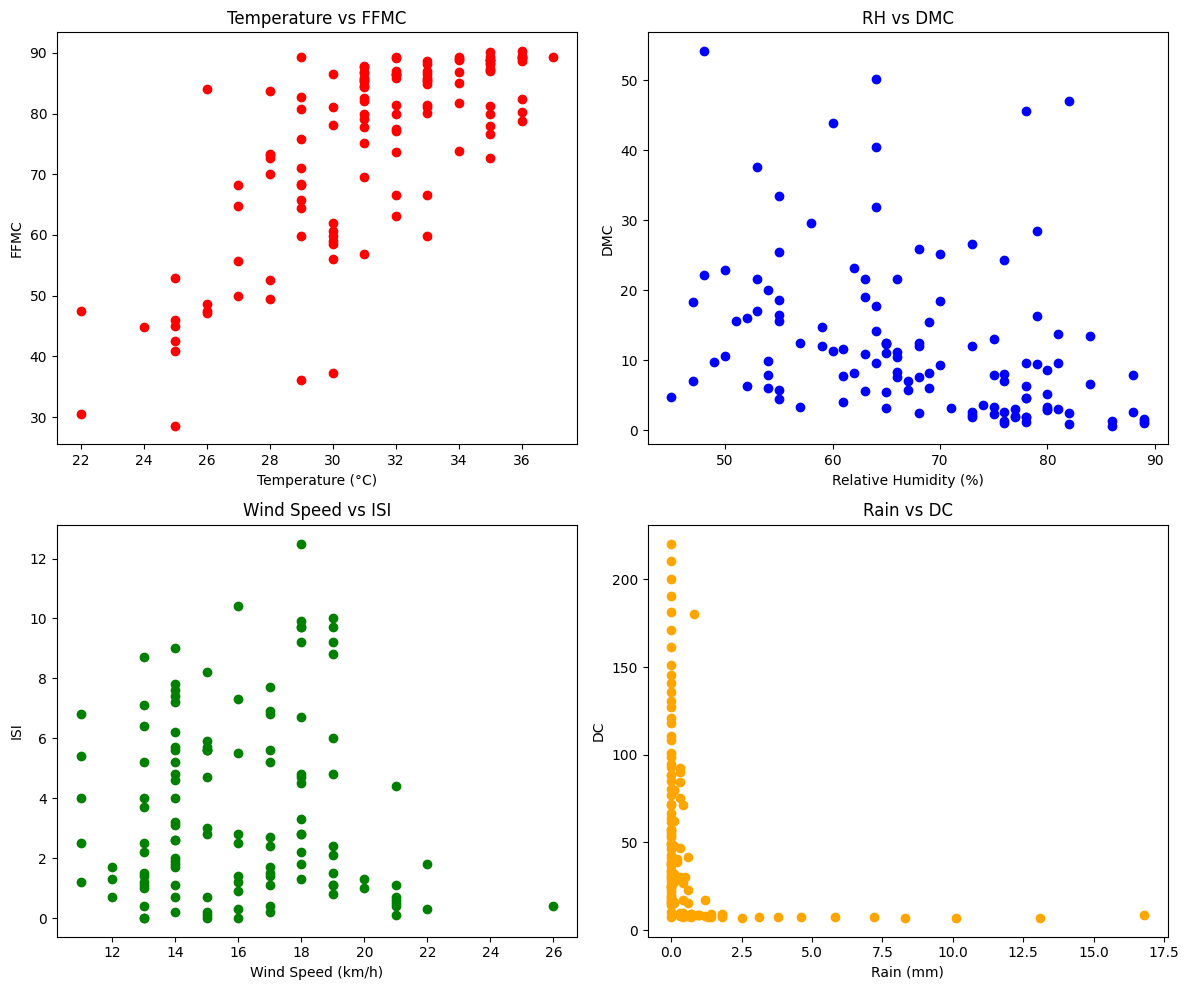

In [182]:
import matplotlib.pyplot as plt
temp = [row[3] for row in data_numeric]
rh = [row[4] for row in data_numeric]
ws = [row[5] for row in data_numeric]
rain = [row[6] for row in data_numeric]
ffmc = [row[7] for row in data_numeric]
dmc = [row[8] for row in data_numeric]
dc = [row[9] for row in data_numeric]
isi = [row[10] for row in data_numeric]

plt.figure(figsize=(12, 10))

# Pair 1: Temperature vs FFMC
plt.subplot(2, 2, 1)
plt.scatter(temp, ffmc, color='red')
plt.xlabel('Temperature (°C)')
plt.ylabel('FFMC')
plt.title('Temperature vs FFMC')

# Pair 2: RH vs DMC
plt.subplot(2, 2, 2)
plt.scatter(rh, dmc, color='blue')
plt.xlabel('Relative Humidity (%)')
plt.ylabel('DMC')
plt.title('RH vs DMC')

# Pair 3: Wind Speed vs ISI
plt.subplot(2, 2, 3)
plt.scatter(ws, isi, color='green')
plt.xlabel('Wind Speed (km/h)')
plt.ylabel('ISI')
plt.title('Wind Speed vs ISI')

# Pair 4: Rain vs DC
plt.subplot(2, 2, 4)
plt.scatter(rain, dc, color='orange')
plt.xlabel('Rain (mm)')
plt.ylabel('DC')
plt.title('Rain vs DC')

plt.tight_layout()
plt.show()


g) Which range-normalized numerical attributes have the largest estimated covariance? What is
the covariance? Create a scatter plot of these range-normalized attributes. [3 points]

In [29]:
normalized = range_normalize_array(data_numeric)
for row in normalized:
    print(row)

#TODO add covariance matrix

[0.0, 0.0, 0, 0.467, 0.273, 0.467, 0.0, 0.601, 0.05, 0.003, 0.104, 0.035, 0.017, 1.0]
[0.033, 0.0, 0, 0.467, 0.364, 0.133, 0.077, 0.58, 0.064, 0.003, 0.08, 0.042, 0.013, 1.0]
[0.067, 0.0, 0, 0.267, 0.841, 0.733, 0.78, 0.3, 0.034, 0.001, 0.024, 0.024, 0.003, 1.0]
[0.1, 0.0, 0, 0.2, 1.0, 0.133, 0.149, 0.0, 0.011, 0.0, 0.0, 0.009, 0.0, 1.0]
[0.133, 0.0, 0, 0.333, 0.727, 0.333, 0.0, 0.587, 0.043, 0.034, 0.096, 0.042, 0.017, 1.0]
[0.167, 0.0, 0, 0.6, 0.5, 0.2, 0.0, 0.875, 0.095, 0.072, 0.248, 0.089, 0.083, 0.0]
[0.2, 0.0, 0, 0.733, 0.205, 0.133, 0.0, 0.966, 0.172, 0.111, 0.512, 0.148, 0.238, 0.0]
[0.233, 0.0, 0, 0.533, 0.636, 0.267, 0.0, 0.94, 0.213, 0.147, 0.448, 0.187, 0.235, 0.0]
[0.267, 0.0, 0, 0.2, 0.977, 0.133, 0.012, 0.394, 0.135, 0.149, 0.032, 0.142, 0.01, 1.0]
[0.3, 0.0, 0, 0.4, 0.773, 0.067, 0.0, 0.723, 0.164, 0.185, 0.104, 0.173, 0.03, 1.0]
[0.333, 0.0, 0, 0.6, 0.455, 0.2, 0.0, 0.906, 0.221, 0.222, 0.32, 0.222, 0.185, 0.0]
[0.367, 0.0, 0, 0.267, 0.818, 0.533, 0.0, 0.898, 0.245, 0

h) Which z-score normalized numerical attributes have the largest estimated correlation
coefficient between them? What is that value? Create a scatter plot for these two z-score
normalized attributes. [3 points]


i) Which z-score normalized numerical attributes have the smallest estimated correlation
coefficient between them? What is that value? Create a scatter plot for these two z-score
normalized attributes. [3 points]


j) How many pairs of numerical features have a correlation greater than or equal to 0.5? [3 points]


k) How many pairs of numerical features have negative estimated covariance? [3 points]


l) Calculate the total variance of the data. [2 points]


m) What is the ratio of the total variance of the data restricted to the five features with the highest
estimated variance to the total estimated variance of the data? [2 points]